In [4]:
import pandas as pd 
import plotly.express as px
import seaborn as sns 
import matplotlib.pyplot as plt 

In [7]:
df=pd.read_csv('Crop_recommendation.csv')
df.columns

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')

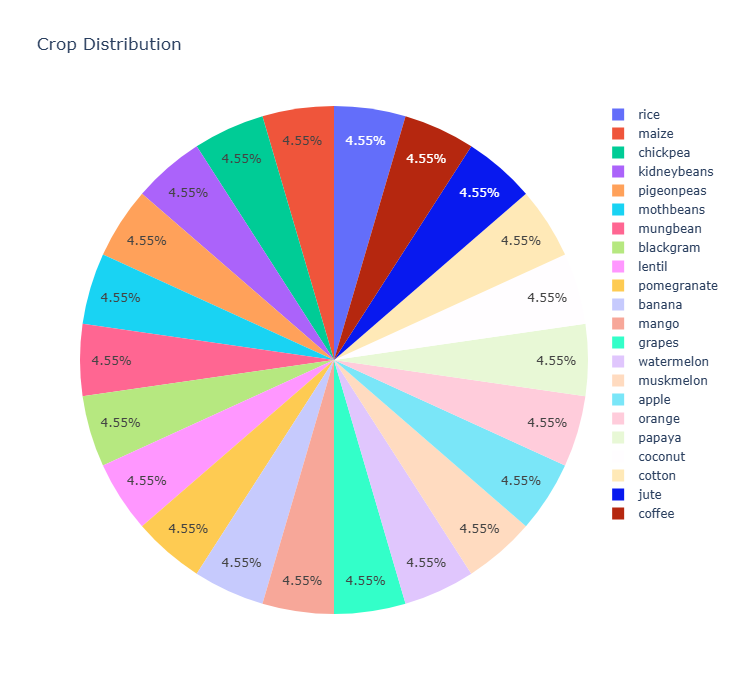

In [8]:
import plotly.express as px

fig = px.pie(df, names="label", title="Crop Distribution")

fig.update_layout(

width=700,

height=700


)

fig.show()

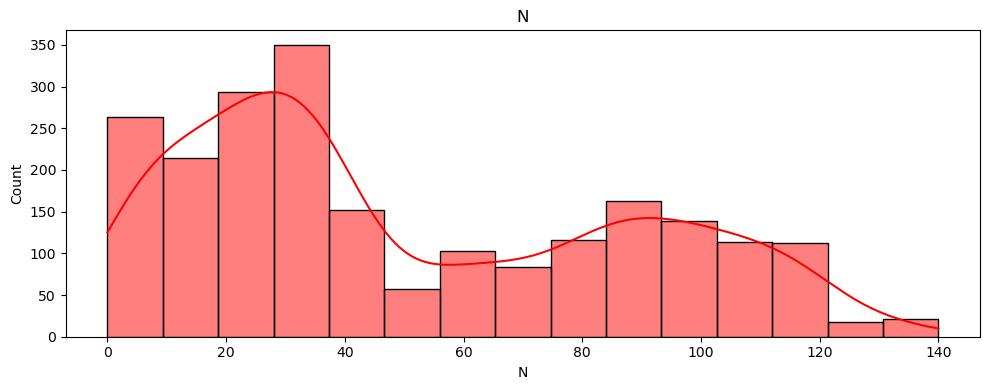

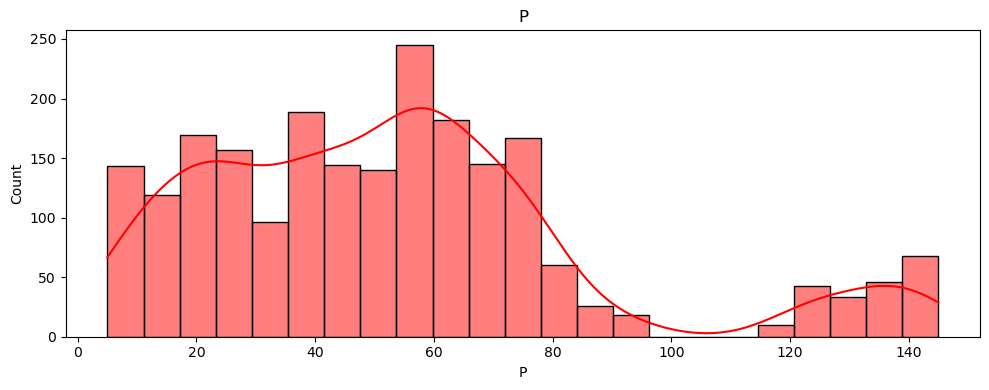

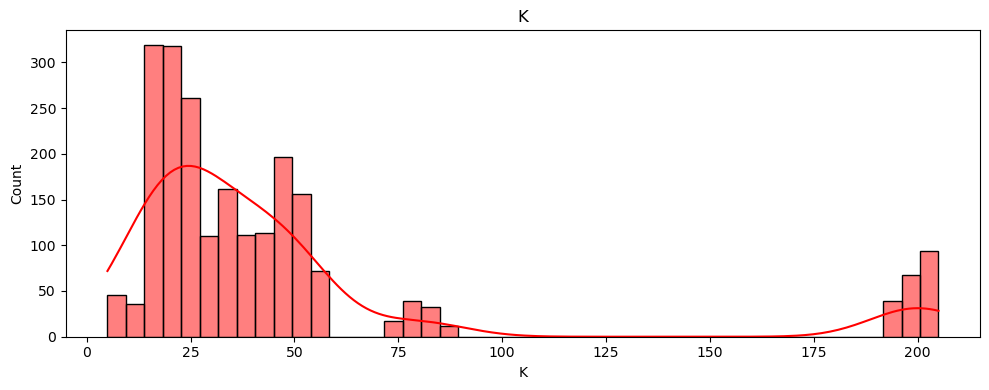

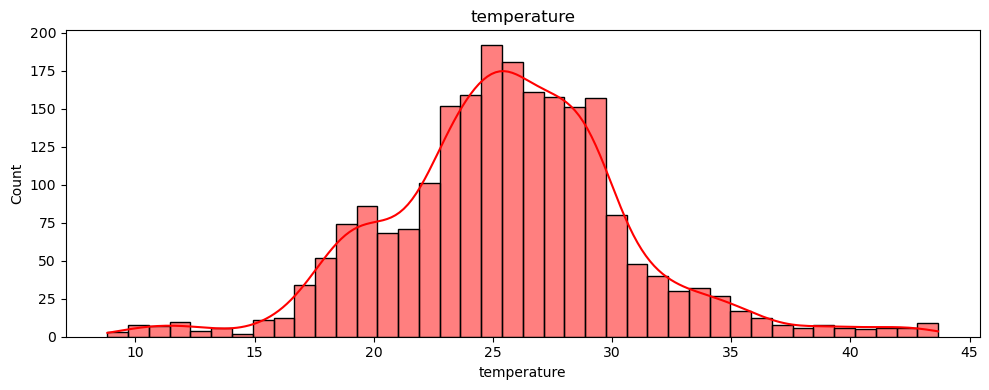

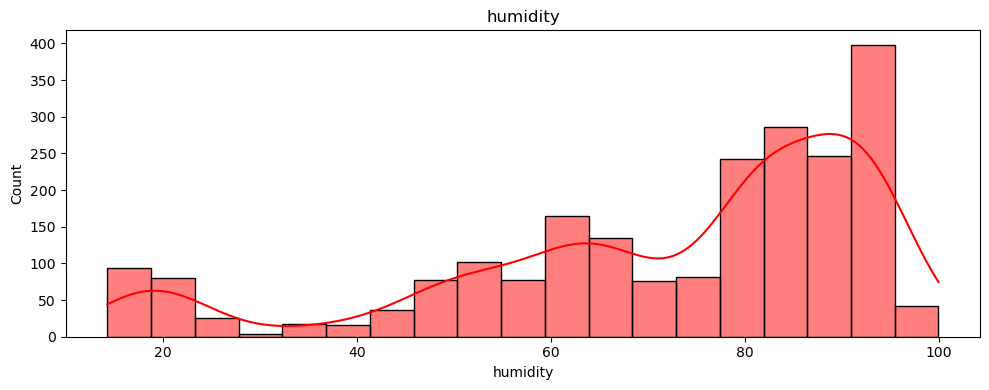

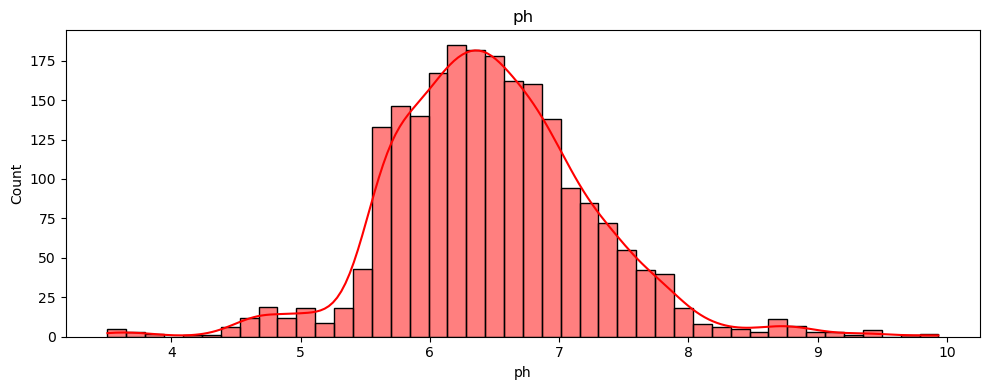

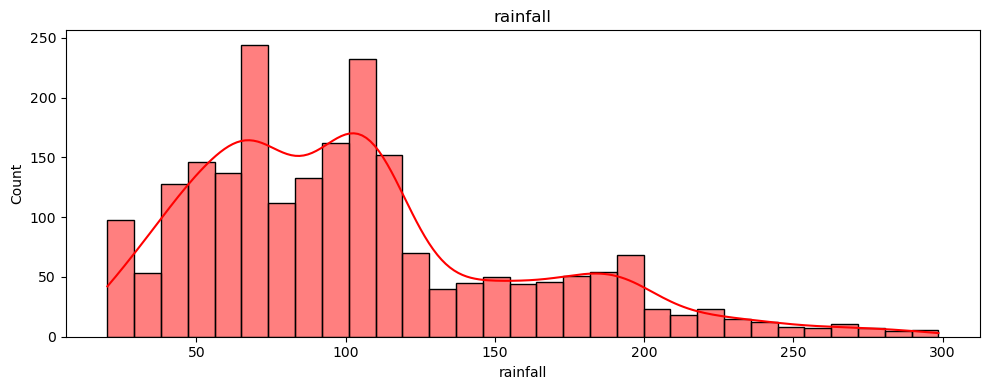

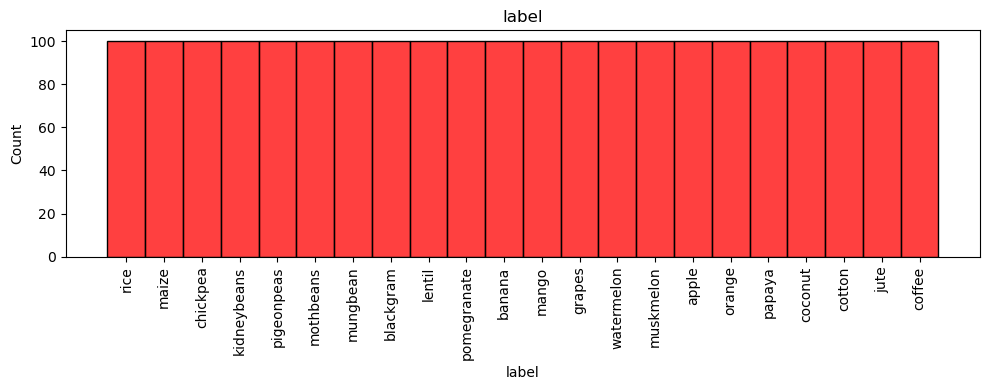

In [15]:
for col in df.columns:
    plt.figure(figsize=(10,4))
    sns.histplot(df[col], kde=(col!='label'), color='red') 
    plt.title(col)
    if col == 'label':
         plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

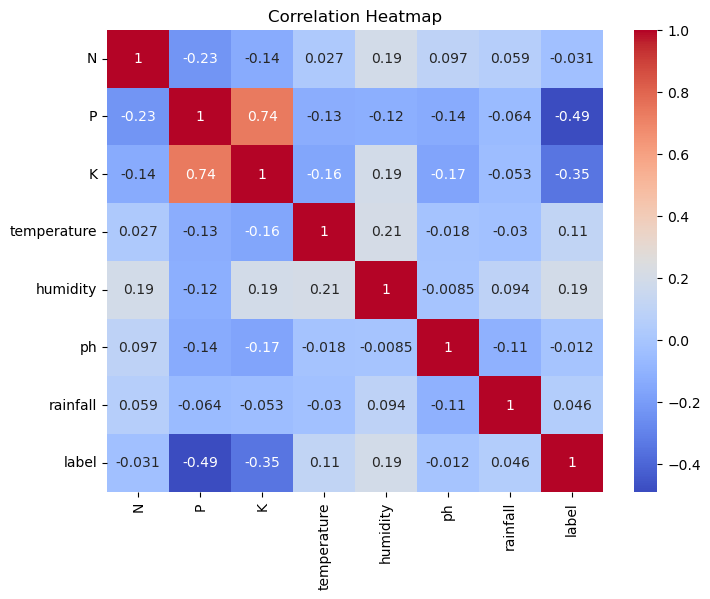

In [16]:
from sklearn.preprocessing import LabelEncoder

df1= df.copy()

le = LabelEncoder()

df1["label"] = le.fit_transform(df1["label"])

plt.figure(figsize=(8,6))

sns.heatmap(df1.corr(), annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

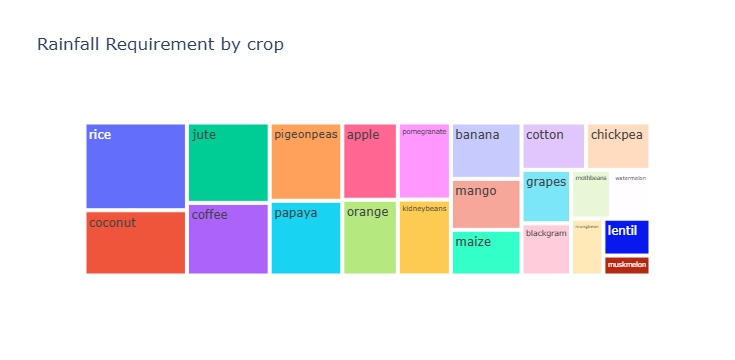

In [17]:
px.treemap(df,
           path=['label'],
           values='rainfall',
           title='Rainfall Requirement by crop').show()


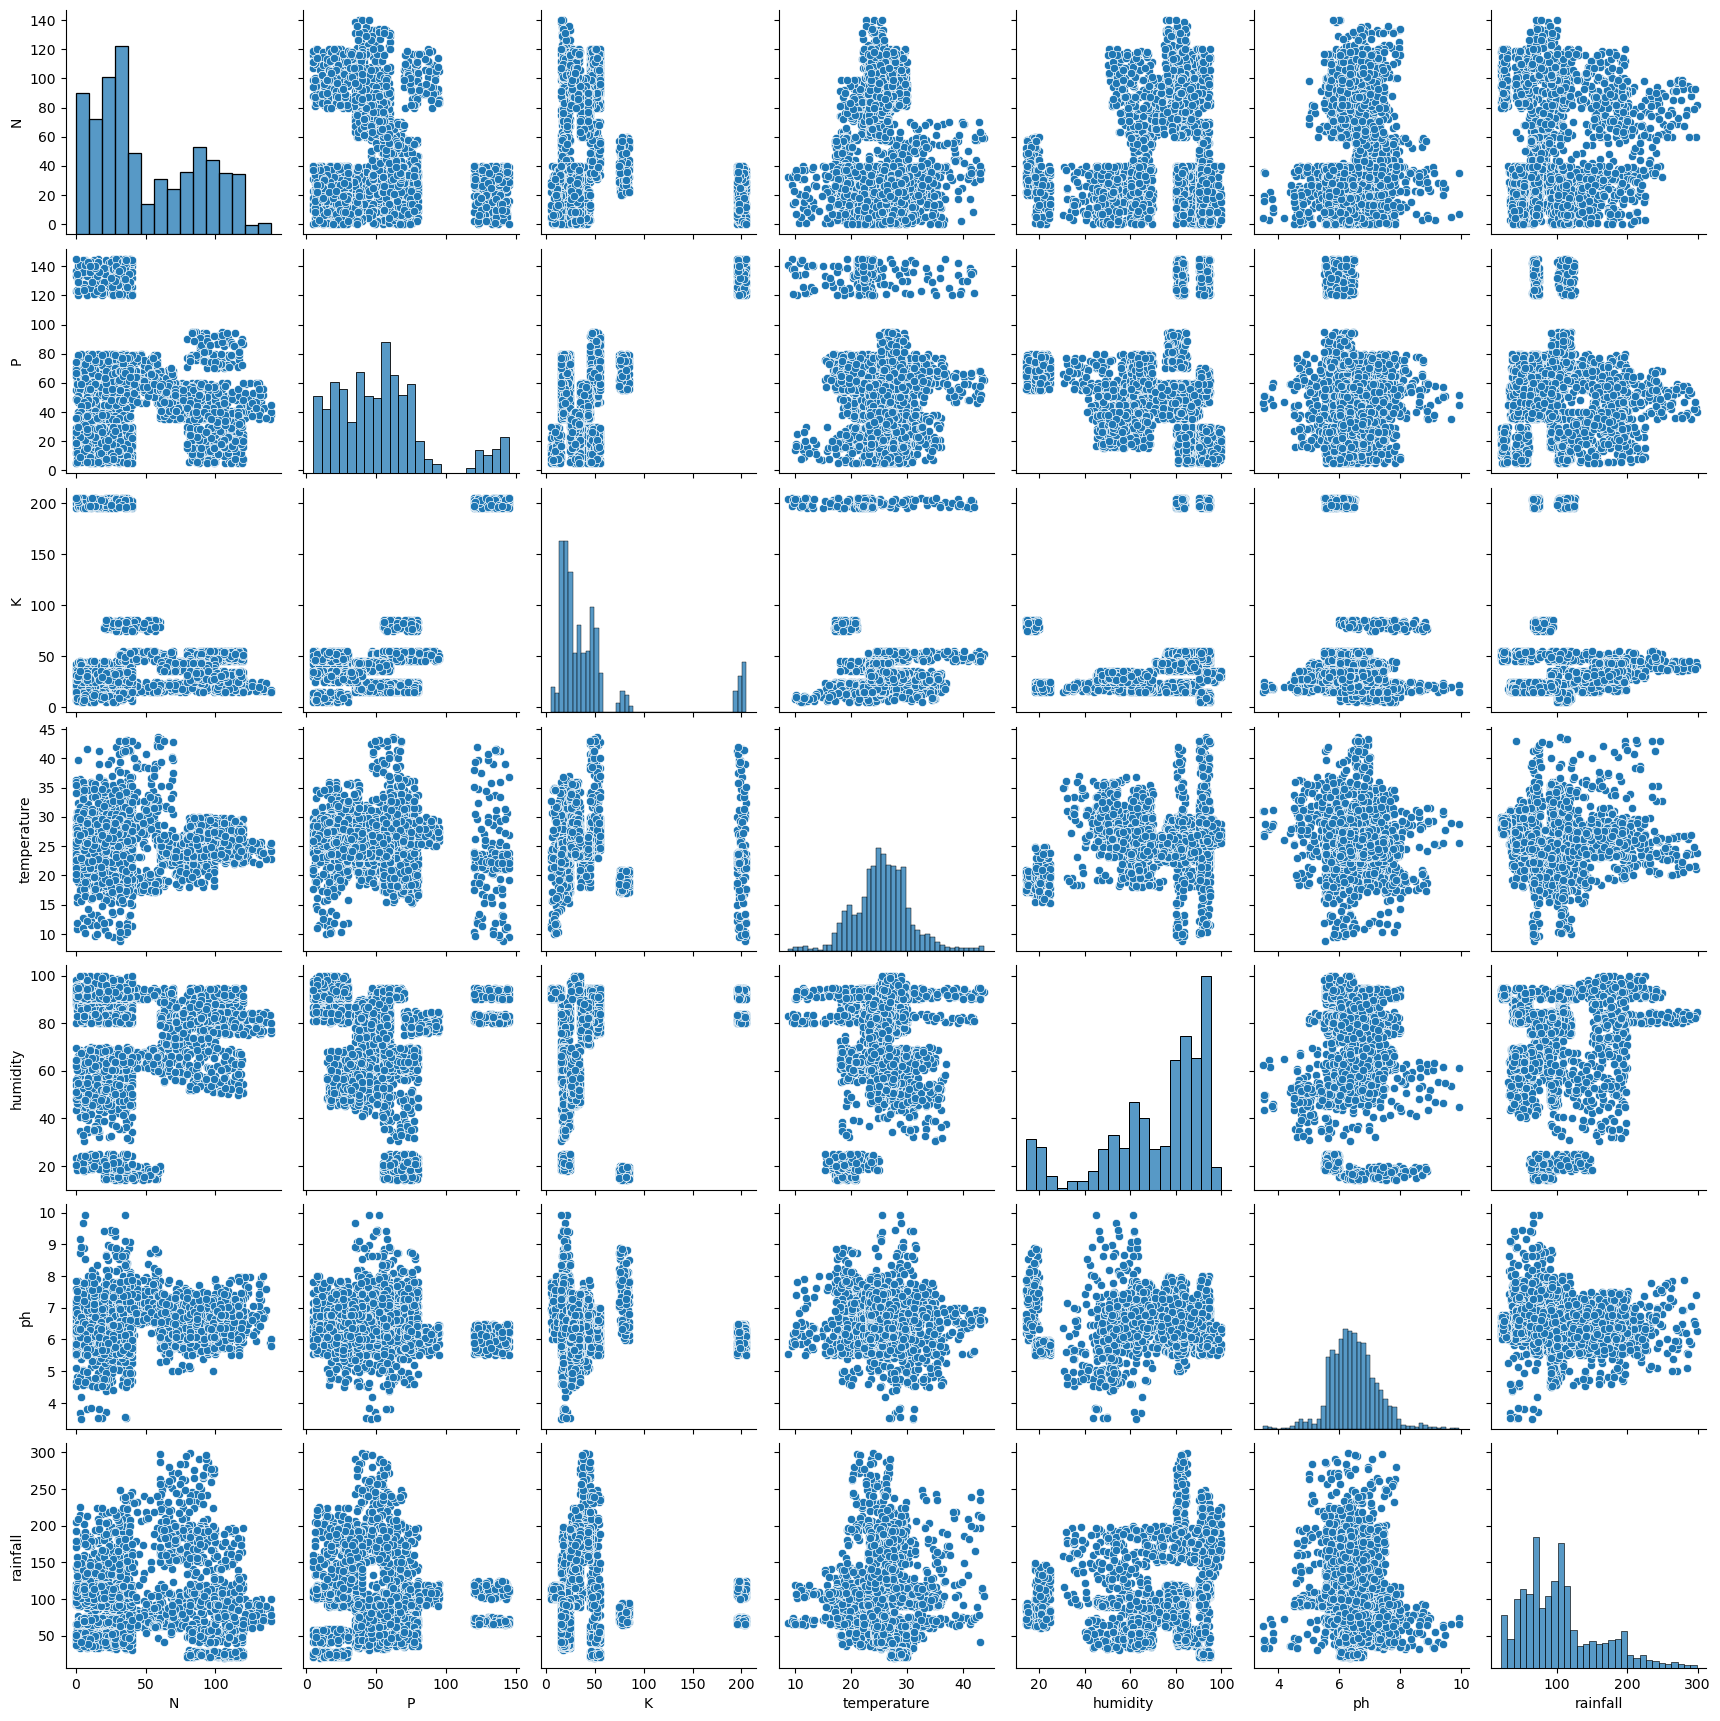

In [18]:
sns.pairplot(df)
plt.show()

In [24]:
x = df.drop("label", axis=1)
y = df["label"]

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [26]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

In [28]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test =scaler.transform(x_test)

In [30]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train, y_train)


,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [32]:
y_pred = knn.predict(x_test)

In [34]:
accuracy = accuracy_score(y_test, y_pred)
print("accuracy:", accuracy)

accuracy: 0.9568181818181818


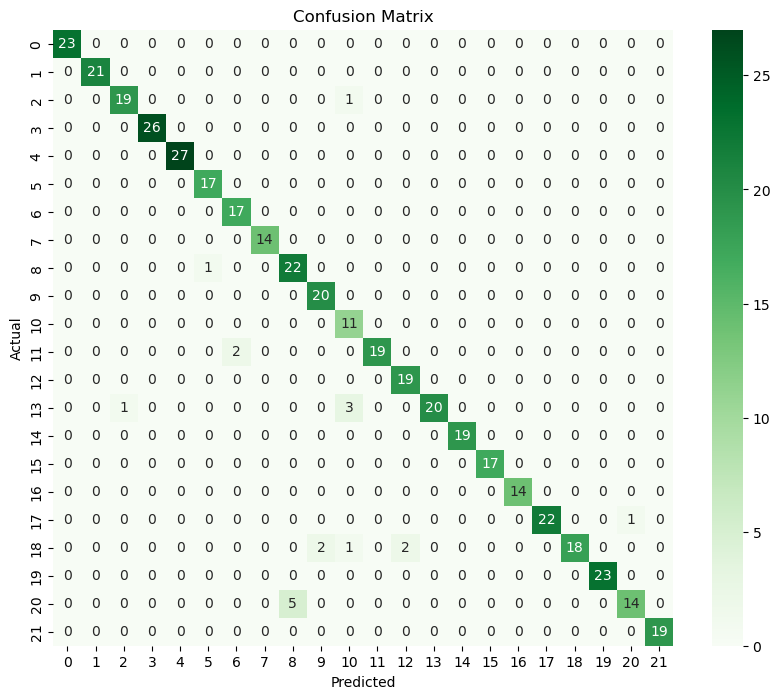

In [35]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [36]:
import joblib
joblib.dump(knn, "Agro_model.pk1")

['Agro_model.pk1']